# Inferencia bayesiana

**Sesión 07 · Estadística II**

En el notebook anterior trabajamos con el paradigma **frecuentista**: la probabilidad es la frecuencia relativa de un suceso cuando repetimos muchas veces un experimento, y los parámetros son valores fijos (aunque desconocidos) sobre los que no se hacen afirmaciones probabilísticas.

La **estadística bayesiana** parte de otra interpretación: **la probabilidad expresa un grado de creencia** en un suceso. Ese grado de creencia puede basarse en conocimiento previo (resultados de estudios anteriores, información de expertos…) y se **actualiza** a medida que observamos datos. En consecuencia:

+ los parámetros desconocidos se describen con **distribuciones de probabilidad**;
+ el resultado de la inferencia es una distribución, la **distribución a posteriori**, que resume todo lo que sabemos del parámetro después de ver los datos;
+ a partir de ella obtenemos lo mismo que en el paradigma frecuentista (estimaciones puntuales, intervalos, comparación de hipótesis), pero **con otra interpretación**.

**Contenido**

1. Probabilidad como grado de creencia
2. El teorema de Bayes
3. Ejercicio: cribado de cáncer de mama
4. El problema de la locomotora
5. Estimaciones puntuales e intervalos de credibilidad
6. Comparación bayesiana de hipótesis
7. Inferencia sobre un parámetro continuo: ¿está sesgada la moneda?
8. Programación probabilística con PyMC
9. Conclusiones

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use('ggplot')
rng = np.random.default_rng(2026)   # semilla fija: los resultados son reproducibles

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


## 1. Probabilidad como grado de creencia

Supongamos que queremos saber qué probabilidad tiene una actriz de ganar el Óscar por su última película. La noción frecuentista de **serie de repeticiones** no está bien definida: cada año la situación es distinta y no hay una serie de experimentos idénticos que podamos imaginar repetidos. La probabilidad entendida como frecuencia no se aplica bien a este tipo de preguntas.

Otro ejemplo: ¿qué probabilidad hay de que un texto anónimo del siglo XVII lo escribiera Cervantes? Para un frecuentista la pregunta no tiene sentido: o lo escribió o no lo escribió, y no hay nada aleatorio. Un bayesiano, en cambio, asigna a ese suceso una probabilidad según su **estado de conocimiento**, y la modifica cuando aparece información nueva (por ejemplo, un análisis estilométrico del texto).

Algunas consecuencias de esta interpretación:

+ Las creencias son de las personas, no de la naturaleza. Dos personas pueden asignar probabilidades distintas a un mismo suceso sin que ninguna se equivoque: simplemente tienen **estados de conocimiento distintos**.
+ Lo importante es cómo **actualizar** esas creencias de forma coherente cuando observamos datos. La herramienta para hacerlo es el **teorema de Bayes**.

> **Sobre la «subjetividad» bayesiana.** «Los métodos bayesianos se califican a menudo de “subjetivos” porque el usuario debe elegir una distribución a priori, es decir, una expresión matemática de la información previa. La distribución a priori requiere información y decisiones del usuario, eso es seguro, pero no es más “subjetiva” que otros aspectos de un procedimiento estadístico, como la elección del modelo para los datos (por ejemplo, una regresión logística), de las variables que se incluyen en una predicción o del contraste estadístico. De hecho, en muchos sentidos los métodos bayesianos pueden ser más “objetivos” que los convencionales, porque están bien adaptados para combinar fuentes de información diversas.»
>
> *Andrew Gelman, profesor de Estadística y Ciencia Política y director del Applied Statistics Center de la Universidad de Columbia.*

## 2. El teorema de Bayes

### 2.1 Enunciado

> **Teorema de Bayes.** Para dos sucesos $A$ y $B$ con $P(B) > 0$:
> $$ P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)} $$

El teorema relaciona las dos probabilidades condicionadas $P(A \mid B)$ y $P(B \mid A)$, y su demostración es pura aritmética a partir de la regla del producto:

+ $P(A, B) = P(A)\,P(B \mid A)$;
+ pero también $P(A, B) = P(B)\,P(A \mid B)$;
+ igualando, $P(A)\,P(B \mid A) = P(B)\,P(A \mid B)$, y basta con dividir entre $P(B)$.

> **Un poco de historia.** El resultado se publicó en 1763, después de la muerte de Thomas Bayes. Pero Bayes solo dedujo un caso particular (cómo «invertir» la distribución binomial); la forma general, tal como la escribimos hoy, se debe a Pierre-Simon Laplace.

### 2.2 Hipótesis y evidencia: actualizar creencias

La lectura habitual del teorema consiste en tomar $A$ como una **hipótesis** $H$ y $B$ como una **evidencia** $E$ (los datos) que debería modificar nuestra creencia en $H$:

$$ P(H \mid E) = \frac{P(E \mid H)\, P(H)}{P(E)} $$

Es la **interpretación diacrónica**: describe cómo debe actualizarse una creencia *a lo largo del tiempo*, cada vez que aparece una evidencia nueva.

| Término | Nombre | Qué representa |
|---|---|---|
| $P(H)$ | probabilidad **a priori** (*prior*) | lo que creíamos sobre $H$ antes de ver los datos |
| $P(E \mid H)$ | **verosimilitud** (*likelihood*) | lo probable que es observar $E$ si $H$ es cierta |
| $P(E)$ | **evidencia** o constante de normalización | lo probable que es observar $E$ en general |
| $P(H \mid E)$ | probabilidad **a posteriori** (*posterior*) | lo que creemos sobre $H$ después de ver los datos |

Si tenemos $n$ hipótesis **mutuamente excluyentes** y **exhaustivas** (exactamente una es cierta), la evidencia se obtiene con la fórmula de la probabilidad total:

$$ P(E) = P(H_1)\,P(E \mid H_1) + \dots + P(H_n)\,P(E \mid H_n) $$

Es decir, $P(E)$ solo sirve para que las probabilidades a posteriori sumen 1.

En la práctica, basta con multiplicar *prior* por verosimilitud para cada hipótesis y **normalizar**:

$$ P(H_i \mid E) \;\propto\; P(H_i)\, P(E \mid H_i) $$

Esta idea cabe en una función de dos líneas que usaremos en todo el notebook:

In [2]:
def bayes(prior, verosimilitud):
    # Probabilidades a posteriori de un conjunto de hipótesis excluyentes y exhaustivas
    no_normalizada = np.asarray(prior) * np.asarray(verosimilitud)
    return no_normalizada / no_normalizada.sum()

### 2.3 Ejemplo: una prueba diagnóstica

Supongamos que en plena epidemia la **prevalencia** de una enfermedad es del 5 %, $P(H_{\text{sí}}) = 0{,}05$, y que a toda la población se le hace una prueba con una **exactitud** del 90 % tanto en enfermos como en sanos: $P(E_{+} \mid H_{\text{sí}}) = P(E_{-} \mid H_{\text{no}}) = 0{,}9$.

¿Qué probabilidad hay de **tener la enfermedad si la prueba ha dado positivo**, $P(H_{\text{sí}} \mid E_{+})$?

$$ P(H_{\text{sí}} \mid E_{+}) = \frac{P(H_{\text{sí}})\,P(E_{+} \mid H_{\text{sí}})}{P(H_{\text{sí}})\,P(E_{+} \mid H_{\text{sí}}) + P(H_{\text{no}})\,P(E_{+} \mid H_{\text{no}})} = \frac{0{,}05 \times 0{,}9}{0{,}05 \times 0{,}9 + 0{,}95 \times 0{,}1} \approx 0{,}32 $$

In [3]:
prior = [0.05, 0.95]                # [enfermo, sano]
verosimilitud = [0.90, 0.10]        # P(positivo | enfermo), P(positivo | sano)

posterior = bayes(prior, verosimilitud)
print(f'P(enfermo | positivo) = {posterior[0]:.3f}')

P(enfermo | positivo) = 0.321


A mucha gente le sorprende que esta probabilidad sea tan inferior al 90 %. Ayuda pensar en **frecuencias**: de cada 10 000 personas, 500 están enfermas y 450 de ellas dan positivo; de las 9500 sanas, 950 dan positivo por error. De los 1400 positivos, solo 450 (un 32 %) están realmente enfermos. Como la enfermedad es poco frecuente, **los falsos positivos de la población sana superan a los verdaderos positivos**.

La animación muestra la misma idea: cada `O` se convierte en una `X` cuando la prueba falla, cosa que ocurre con una frecuencia $1 - P(E_{+} \mid H_{\text{sí}})$.

![Teorema de Bayes en una prueba diagnóstica](https://raw.githubusercontent.com/simplystats/simplystats.github.io/master/_images/bayes.gif)

### 2.4 Ejemplo: el problema de Monty Hall

*Let's Make a Deal* fue un concurso de la televisión estadounidense presentado por Monty Hall. Una de sus pruebas se ha convertido en un problema clásico de probabilidad:

+ El concursante debe elegir entre tres puertas cerradas. Detrás de una hay un coche; detrás de las otras dos, una cabra.
+ El concursante elige una puerta, por ejemplo la **A**, sin abrirla. El presentador, que sabe dónde está el coche, abre otra puerta, por ejemplo la **B**, y muestra una cabra.
+ Entonces pregunta: «¿Quiere cambiar a la puerta **C**?». ¿Le conviene cambiar?

Casi todo el mundo piensa que da igual cambiar o no. Es falso: **si mantiene la elección, gana con probabilidad 1/3; si cambia, con probabilidad 2/3.**

Veámoslo con el teorema de Bayes. Las hipótesis son la posición del coche, y al principio todas son igual de probables:

$$ P(H = A) = P(H = B) = P(H = C) = 1/3 $$

La evidencia $E$ es que «el presentador abre la puerta B». Su verosimilitud bajo cada hipótesis, sabiendo que hemos elegido A y que el presentador nunca abre ni nuestra puerta ni la del coche, es:

+ si el coche está en A, el presentador puede abrir B o C, y elige B la mitad de las veces: $P(E \mid H = A) = 1/2$;
+ si el coche está en B, nunca abrirá B: $P(E \mid H = B) = 0$;
+ si el coche está en C, está obligado a abrir B: $P(E \mid H = C) = 1$.

Por tanto, la probabilidad de ganar si mantenemos la puerta A es:

$$ P(H = A \mid E) = \frac{1/3 \times 1/2}{1/3 \times 1/2 + 1/3 \times 0 + 1/3 \times 1} = \frac{1}{3} $$

Como las probabilidades a posteriori suman 1 y $P(H = B \mid E) = 0$, la probabilidad de ganar si cambiamos a C es $1 - 1/3 = 2/3$.

> **No eres el único.** Según cuenta Samuel Arbesman en *Wired* (26/11/2014), cuando le plantearon el problema a Paul Erdős, uno de los matemáticos más prolíficos del siglo XX y un experto en probabilidad, tampoco entendió por qué abrir una puerta cambiaba nada. Aun después de ver la demostración varias veces no quedó convencido, y tardó varios días en aceptar la solución.

Si la demostración no te convence, comprobémoslo por simulación:

In [4]:
def juega(cambiar):
    # Simula una partida y devuelve True si el concursante gana el coche
    coche = rng.integers(3)
    eleccion = rng.integers(3)
    abre = rng.choice([p for p in range(3) if p not in (eleccion, coche)])   # nunca abre la elegida ni la del coche
    if cambiar:
        eleccion = next(p for p in range(3) if p not in (eleccion, abre))
    return eleccion == coche


n_partidas = 20_000
print(f'Proporción de victorias si mantenemos la puerta: {np.mean([juega(False) for _ in range(n_partidas)]):.1%}')
print(f'Proporción de victorias si cambiamos de puerta:  {np.mean([juega(True) for _ in range(n_partidas)]):.1%}')

Proporción de victorias si mantenemos la puerta: 33.7%
Proporción de victorias si cambiamos de puerta:  66.4%


**Ejercicio 1**

Calcula $P(H = C \mid E)$ aplicando directamente el teorema de Bayes (puedes usar la función `bayes`) y comprueba que coincide con el resultado de la simulación.

In [5]:
# Escribe aquí tu solución

## 3. Ejercicio: cribado de cáncer de mama

**¿Qué nos dice el resultado de una prueba clínica?** 

Los datos son los siguientes:

+ El 1 % de las mujeres de cuarenta años que participan en un cribado rutinario tiene cáncer de mama.
+ El 80 % de las mujeres con cáncer de mama obtiene una mamografía positiva.
+ El 9,6 % de las mujeres sin cáncer de mama obtiene también una mamografía positiva.

Una mujer de este grupo de edad ha obtenido una mamografía positiva en un cribado rutinario.

Con la notación de la sección 2:

| | $P(H)$ | $P(+ \mid H)$ | $P(- \mid H)$ |
|---|:---:|:---:|:---:|
| Cáncer | 0,01 | 0,8 | 0,2 |
| Sin cáncer | 0,99 | 0,096 | 0,904 |

Este problema parece sencillo, pero no lo es tanto en la práctica: cuando se plantea a médicos, solo en torno al 15 % da con la respuesta correcta.

**Ejercicio 2**

a) ¿Qué probabilidad hay de que tenga realmente cáncer de mama? Recuerda que $P(E) = \sum_i P(H_i)\, P(E \mid H_i)$.

In [6]:
# Escribe aquí tu solución

b) ¿Es una «buena» prueba para detectar el cáncer de mama? *Pista:* compara las cantidades $P(\text{cáncer})\,P(+ \mid \text{cáncer})$ y $P(\text{sin cáncer})\,P(+ \mid \text{sin cáncer})$, que son proporcionales a las dos probabilidades a posteriori.

In [7]:
# Escribe aquí tu solución

**Ejercicio 3**

Supongamos que el resultado de una segunda mamografía es **independiente** del de la primera (en la realidad es un supuesto claramente falso, pero aceptémoslo). ¿Qué probabilidad hay de que tenga cáncer si la segunda prueba también da positivo?

*Pista:* la probabilidad a posteriori después de la primera prueba es la probabilidad a priori de la segunda.

In [8]:
# Escribe aquí tu solución

## 4. El problema de la locomotora

### 4.1 Planteamiento

Una compañía ferroviaria numera sus locomotoras en orden: $1, 2, \dots, N$. Un día vemos una locomotora con el número 60. **¿Cuántas locomotoras tiene la compañía?**

> **Un problema con historia.** Durante la Segunda Guerra Mundial, la División de Guerra Económica de la embajada estadounidense en Londres usó el análisis estadístico para estimar la producción alemana de tanques y otro material. Los aliados habían capturado registros con los números de serie de chasis y motores de tanques concretos, y el análisis mostró que los números se asignaban en bloques de 100, de forma secuencial dentro de cada bloque. El problema de estimar la producción se reducía, dentro de cada bloque, al problema de la locomotora. Las estimaciones de los analistas fueron muy inferiores a las de otras fuentes de inteligencia y, como se comprobó después de la guerra, mucho más precisas.
>
> *Fuente: A. B. Downey, [Think Bayes](https://greenteapress.com/wp/think-bayes/).*

Lo único seguro es que $N \geq 60$. Para razonar de forma bayesiana necesitamos responder dos preguntas:

1. ¿Qué sabíamos sobre $N$ **antes de ver los datos**? Es la distribución **a priori**, $P(H)$.
2. Para cada valor posible de $N$, ¿qué probabilidad hay de observar los datos (una locomotora con el número 60)? Es la **verosimilitud**, $P(E \mid H)$.

### 4.2 Distribución a priori y verosimilitud

No tenemos mucha base para elegir una distribución a priori, así que empezamos por algo sencillo: $N$ puede ser **cualquier valor entre 1 y 1000, todos con la misma probabilidad** (distribución a priori *uniforme*). Cada valor de $N$ es una hipótesis.

In [9]:
hipotesis = np.arange(1, 1001)                            # valores posibles de N
prior_unif = np.full(len(hipotesis), 1 / len(hipotesis))  # todas igual de probables

Para la verosimilitud: si la compañía tiene $N$ locomotoras y es igual de probable ver cualquiera de ellas, la probabilidad de ver una concreta es $1/N$. Y es imposible ver la número 60 si hay menos de 60:

$$ P(\text{ver la n.º } k \mid N) = \begin{cases} 1/N & \text{si } N \geq k \\ 0 & \text{si } N < k \end{cases} $$

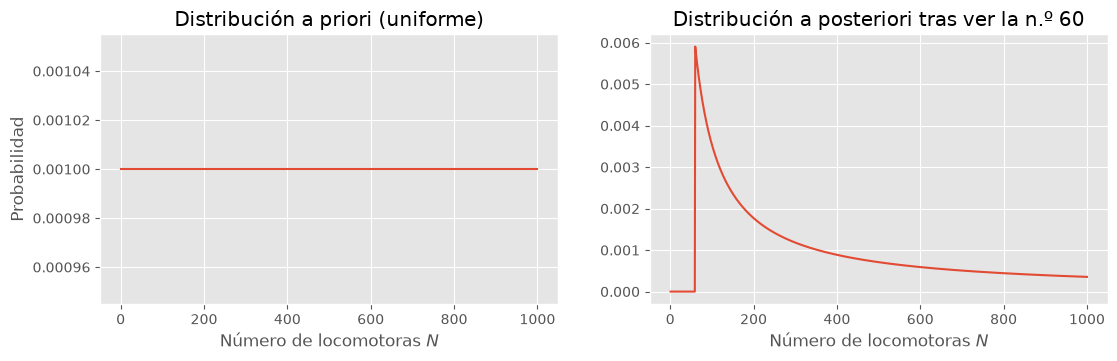

In [10]:
def verosimilitud_loco(k, hipotesis):
    # P(ver la locomotora número k | N) para cada valor N de las hipótesis
    return np.where(hipotesis >= k, 1 / hipotesis, 0)


posterior = bayes(prior_unif, verosimilitud_loco(60, hipotesis))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.5), sharex=True)
ax1.plot(hipotesis, prior_unif)
ax1.set_title('Distribución a priori (uniforme)')
ax1.set_xlabel('Número de locomotoras $N$')
ax1.set_ylabel('Probabilidad')
ax2.plot(hipotesis, posterior)
ax2.set_title('Distribución a posteriori tras ver la n.º 60')
ax2.set_xlabel('Número de locomotoras $N$')
plt.show()

### 4.3 Resumir la distribución a posteriori

La distribución a posteriori contiene todo lo que sabemos de $N$. Si hay que dar un único valor, el **más probable** es 60. Parece una mala apuesta (¿qué probabilidad hay de haber visto justo la locomotora con el número más alto?), pero si el objetivo es acertar el valor exacto, es la mejor.

> Si lo que queremos es minimizar el error de estimación, primero debemos decidir cómo medimos ese error. Si penalizamos especialmente los errores grandes, utilizando el error cuadrático, la mejor estimación es la media de la distribución a posteriori. Esto se debe a que la media es precisamente el valor que minimiza el error cuadrático esperado, teniendo en cuenta todos los posibles valores de \(N\) y sus probabilidades.

> Así, aunque 60 sea el valor individual más probable, la media puede ser una mejor estimación cuando nos importa no alejarnos demasiado del valor real. La elección depende, por tanto, de qué entendamos por equivocarnos.

Si lo que queremos es minimizar el error medio, una alternativa es la **media de la distribución a posteriori** (la *estimación de Bayes*):

$$ \hat{N} = \mathbb{E}[N \mid E] = \sum_N N \cdot P(N \mid E) $$

In [11]:
def media_posterior(hipotesis, posterior):
    return np.sum(hipotesis * posterior)


print(f'Media a posteriori: {media_posterior(hipotesis, posterior):.0f} locomotoras')

Media a posteriori: 333 locomotoras


### 4.4 Más datos: actualización secuencial

Hay dos maneras de mejorar la estimación: **obtener más datos** u **obtener más información de contexto** para mejorar la distribución a priori.

Supongamos que, además de la 60, vemos las locomotoras 30 y 90. Basta con aplicar el teorema de Bayes una vez por dato: **la distribución a posteriori después de un dato es la distribución a priori del siguiente** (el orden en que llegan los datos no afecta al resultado final).

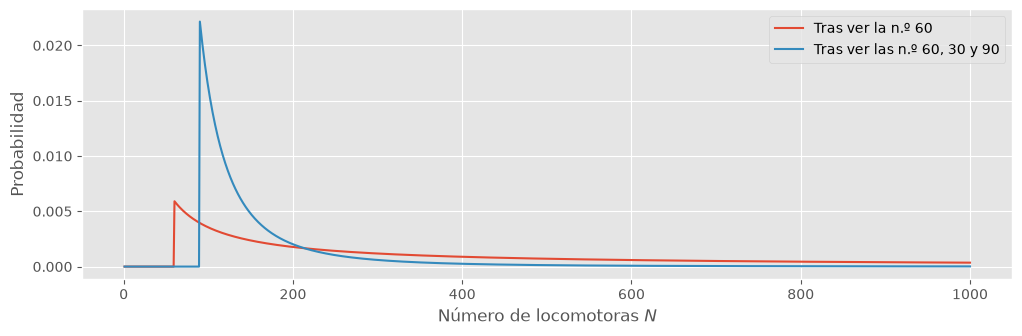

Media a posteriori con tres observaciones: 164 locomotoras


In [12]:
def actualiza(prior, datos, hipotesis):
    # Aplica el teorema de Bayes secuencialmente, un dato tras otro
    posterior = prior
    for k in datos:
        posterior = bayes(posterior, verosimilitud_loco(k, hipotesis))
    return posterior


datos_loco = [60, 30, 90]
posterior3 = actualiza(prior_unif, datos_loco, hipotesis)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(hipotesis, posterior, label='Tras ver la n.º 60')
ax.plot(hipotesis, posterior3, label='Tras ver las n.º 60, 30 y 90')
ax.set_xlabel('Número de locomotoras $N$')
ax.set_ylabel('Probabilidad')
ax.legend()
plt.show()

print(f'Media a posteriori con tres observaciones: {media_posterior(hipotesis, posterior3):.0f} locomotoras')

### 4.5 ¿Cuánto depende el resultado de la distribución a priori?

El límite superior de 1000 era arbitrario. Veamos cómo cambia la media a posteriori si usamos otros límites:

In [13]:
filas = {}
for limite in [500, 1000, 2000]:
    h = np.arange(1, limite + 1)
    prior = np.full(len(h), 1 / len(h))
    filas[f'Uniforme 1-{limite}'] = [media_posterior(h, actualiza(prior, [60], h)),
                                     media_posterior(h, actualiza(prior, datos_loco, h))]

pd.DataFrame(filas, index=['Tras ver la n.º 60', 'Tras ver las n.º 60, 30 y 90']).T.round(0)

,Tras ver la n.º 60,"Tras ver las n.º 60, 30 y 90"
Uniforme 1-500,207.0,152.0
Uniforme 1-1000,333.0,164.0
Uniforme 1-2000,552.0,171.0


Con una sola observación, el resultado depende muchísimo del límite elegido; con tres, bastante menos. Es un resultado general: **a medida que llegan datos, las distribuciones a posteriori obtenidas con distribuciones a priori distintas tienden a converger**. Los datos acaban dominando sobre las creencias iniciales.

### 4.6 Una distribución a priori más informada

Si no hay más datos, podemos mejorar la distribución a priori con **información de contexto**. No parece razonable suponer que una compañía con 1000 locomotoras es tan probable como una con una sola: hay muchas compañías pequeñas y pocas grandes.

El tamaño de las empresas suele seguir una **ley de potencias**: si hay 1000 compañías con menos de 10 locomotoras, puede haber 100 con 100 locomotoras, 10 con 1000 y quizá una con 10 000. Matemáticamente, la probabilidad de un tamaño $N$ es inversamente proporcional a $N$:

$$ P(N) \;\propto\; \left(\frac{1}{N}\right)^{\alpha} $$

donde $\alpha$ es un parámetro que suele estar cerca de 1.

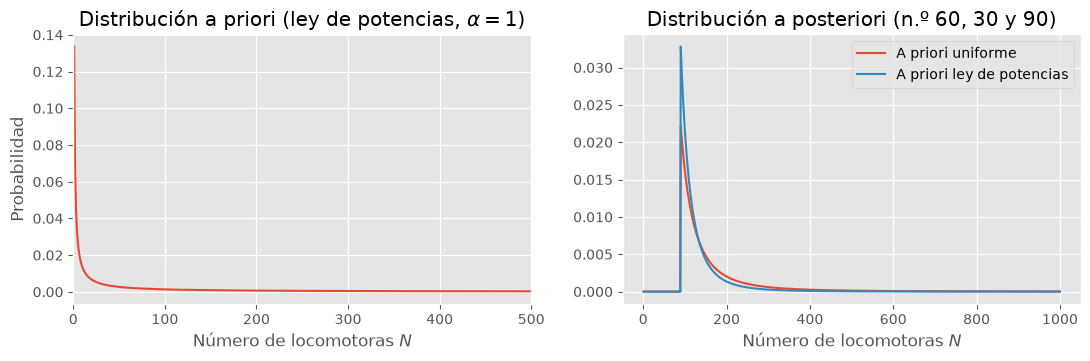

Ley de potencias 1-500: media a posteriori = 131
Ley de potencias 1-1000: media a posteriori = 133
Ley de potencias 1-2000: media a posteriori = 134


In [14]:
def prior_potencias(hipotesis, alpha=1.0):
    p = hipotesis ** (-alpha)
    return p / p.sum()


prior_pot = prior_potencias(hipotesis)
posterior_pot = actualiza(prior_pot, datos_loco, hipotesis)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.5))
ax1.plot(hipotesis, prior_pot)
ax1.set_xlim(0, 500)
ax1.set_title('Distribución a priori (ley de potencias, $\\alpha = 1$)')
ax1.set_xlabel('Número de locomotoras $N$')
ax1.set_ylabel('Probabilidad')
ax2.plot(hipotesis, posterior3, label='A priori uniforme')
ax2.plot(hipotesis, posterior_pot, label='A priori ley de potencias')
ax2.set_title('Distribución a posteriori (n.º 60, 30 y 90)')
ax2.set_xlabel('Número de locomotoras $N$')
ax2.legend()
plt.show()

for limite in [500, 1000, 2000]:
    h = np.arange(1, limite + 1)
    print(f'Ley de potencias 1-{limite}: media a posteriori = '
          f'{media_posterior(h, actualiza(prior_potencias(h), datos_loco, h)):.0f}')

Con una distribución a priori más realista, la estimación **apenas depende del límite superior** que elijamos: la información de contexto ha hecho el resultado más robusto.

## 5. Estimaciones puntuales e intervalos de credibilidad

### 5.1 Resumir la distribución a posteriori

Una vez obtenida la distribución a posteriori, solemos resumirla con:

+ una **estimación puntual**: la media, la mediana o la **moda** de la distribución a posteriori. La moda, el valor más probable, se denomina **estimación de máximo a posteriori (MAP)**;
+ un **intervalo de credibilidad**: dos valores entre los que el parámetro se encuentra con una probabilidad dada, por ejemplo del 95 %.

La forma más sencilla de obtener el intervalo de credibilidad del 95 % es acumular las probabilidades de la distribución a posteriori y quedarse con los valores en los que la probabilidad acumulada alcanza el 2,5 % y el 97,5 %: es decir, los **percentiles 2,5 y 97,5** de la distribución a posteriori. Lo calculamos para la locomotora con la distribución a priori de ley de potencias y las tres observaciones:

MAP (moda):                     90
Mediana:                        113
Media:                          133
Intervalo de credibilidad 95 %: [90, 303]


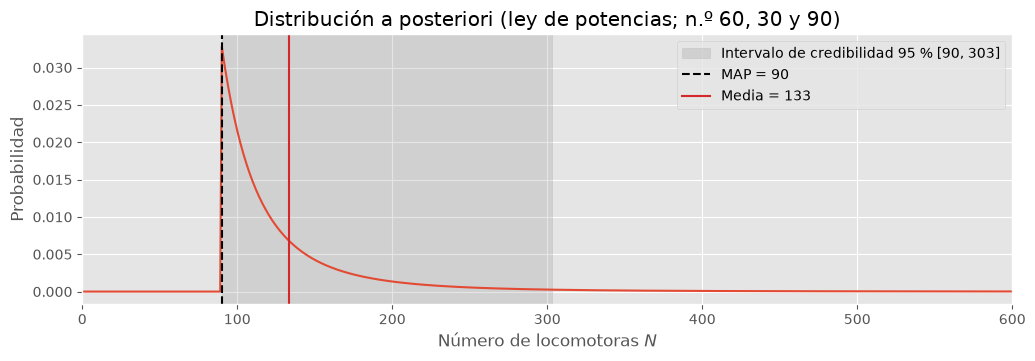

In [15]:
def percentil_posterior(hipotesis, posterior, q):
    # Primer valor de la hipótesis cuya probabilidad acumulada alcanza q (en %)
    return hipotesis[np.searchsorted(np.cumsum(posterior), q / 100)]


media = media_posterior(hipotesis, posterior_pot)
mediana = percentil_posterior(hipotesis, posterior_pot, 50)
map_ = hipotesis[np.argmax(posterior_pot)]
inf, sup = percentil_posterior(hipotesis, posterior_pot, 2.5), percentil_posterior(hipotesis, posterior_pot, 97.5)

print(f'MAP (moda):                     {map_}')
print(f'Mediana:                        {mediana}')
print(f'Media:                          {media:.0f}')
print(f'Intervalo de credibilidad 95 %: [{inf}, {sup}]')

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(hipotesis, posterior_pot)
ax.axvspan(inf, sup, color='0.5', alpha=0.2, label=f'Intervalo de credibilidad 95 % [{inf}, {sup}]')
ax.axvline(map_, color='black', lw=1.5, ls='--', label=f'MAP = {map_}')
ax.axvline(media, color='tab:red', lw=1.5, label=f'Media = {media:.0f}')
ax.set_xlim(0, 600)
ax.set_xlabel('Número de locomotoras $N$')
ax.set_ylabel('Probabilidad')
ax.set_title('Distribución a posteriori (ley de potencias; n.º 60, 30 y 90)')
ax.legend()
plt.show()

La anchura del intervalo indica, con razón, que todavía hay **mucha incertidumbre** sobre el número de locomotoras.

### 5.2 Intervalo de credibilidad frente a intervalo de confianza

Los dos se calculan de forma parecida, pero responden a preguntas distintas:

+ En el **intervalo de confianza** frecuentista (notebook anterior), el 95 % es una propiedad del **procedimiento**: si repitiéramos el muestreo muchas veces, el 95 % de los intervalos contendría el parámetro. De un intervalo concreto **no** podemos decir que contiene el parámetro con probabilidad 0,95.
+ En el **intervalo de credibilidad** bayesiano, el parámetro es una variable aleatoria (describe nuestra incertidumbre sobre él), así que **sí podemos decir que, dados los datos y la distribución a priori, hay un 95 % de probabilidad de que $N$ esté entre los dos extremos**. Es precisamente la interpretación que intuitivamente (y erróneamente) se suele dar a los intervalos de confianza.

El precio de esta interpretación más directa es que el resultado **depende de la distribución a priori**, que hay que elegir y justificar.

## 6. Comparación bayesiana de hipótesis

### 6.1 La pregunta que realmente nos interesa

Volvamos al efecto aparente del notebook anterior: *¿la duración media del embarazo de los primeros hijos es mayor que la de los demás hijos?*

En el contraste de hipótesis frecuentista calculamos el valor *p*, es decir, la probabilidad de observar un efecto al menos tan grande como el observado **suponiendo que $H_0$ es cierta**: $P(E \mid H_0)$. Pero $P(E \mid H_0) \neq P(H_0 \mid E)$: el valor *p* **no** es la probabilidad de que el efecto sea real o se deba al azar.

El enfoque bayesiano calcula directamente lo que nos interesa, $P(H_A \mid E)$, la probabilidad de que el efecto sea real a la vista de los datos:

$$ P(H_A \mid E) = \frac{P(E \mid H_A)\, P(H_A)}{P(E \mid H_A)\, P(H_A) + P(E \mid H_0)\, P(H_0)} $$

Para ello necesitamos dos verosimilitudes, $P(E \mid H_0)$ y $P(E \mid H_A)$, y las probabilidades a priori de cada hipótesis.

### 6.2 Las verosimilitudes

Cargamos los datos de la NSFG igual que en el notebook anterior. La evidencia $E$ es «una diferencia de medias, en valor absoluto, al menos tan grande como la observada».

In [16]:
# Datos de embarazos de la NSFG (2002), como en el notebook anterior
nsfg = pd.read_fwf(
    'files/2002FemPreg.dat',
    colspecs=[(0, 12), (274, 276), (276, 277), (277, 279), (422, 440)],
    names=['caseid', 'prglength', 'outcome', 'birthord', 'finalwgt'],
).fillna({'birthord': 0})

nacidos_vivos = nsfg[nsfg.outcome == 1]
x = nacidos_vivos.loc[nacidos_vivos.birthord == 1, 'prglength'].to_numpy()   # primeros hijos
y = nacidos_vivos.loc[nacidos_vivos.birthord >= 2, 'prglength'].to_numpy()   # demás hijos
n1, n2 = len(x), len(y)

diferencia_obs = abs(x.mean() - y.mean())
print(f'Diferencia de medias observada: {diferencia_obs:.3f} semanas')

Diferencia de medias observada: 0.078 semanas


+ **$P(E \mid H_0)$**: si no hay efecto, las dos muestras vienen de la misma población. Es exactamente el valor *p* bilateral que obtuvimos con el **test de permutaciones** (notebook anterior).
+ **$P(E \mid H_A)$**: si el efecto es real, cada grupo viene de su propia población. Simulamos nuevas muestras de cada grupo por separado con ***bootstrap*** (remuestreando cada grupo con reemplazo) y contamos con qué frecuencia la diferencia es al menos tan grande como la observada.

In [17]:
n_sim = 2000

# P(E | H0): permutamos las etiquetas (los dos grupos vienen de la misma población)
conjunto = np.concatenate([x, y])
dif_h0 = np.empty(n_sim)
for i in range(n_sim):
    perm = rng.permutation(conjunto)
    dif_h0[i] = abs(perm[:n1].mean() - perm[n1:].mean())

# P(E | HA): remuestreamos cada grupo por separado (cada uno con su propia población)
dif_ha = np.empty(n_sim)
for i in range(n_sim):
    dif_ha[i] = abs(rng.choice(x, size=n1).mean() - rng.choice(y, size=n2).mean())

p_e_h0 = np.mean(dif_h0 >= diferencia_obs)
p_e_ha = np.mean(dif_ha >= diferencia_obs)
print(f'P(E | H0) = {p_e_h0:.3f}   (el valor p del notebook anterior)')
print(f'P(E | HA) = {p_e_ha:.3f}')

P(E | H0) = 0.161   (el valor p del notebook anterior)
P(E | HA) = 0.492


Bajo $H_A$, una diferencia al menos tan grande como la observada aparece aproximadamente la mitad de las veces, lo cual es lógico: estamos suponiendo que el efecto real es precisamente el observado.

> **Una simplificación.** $P(E \mid H_A)$ depende de qué tamaño de efecto supongamos bajo $H_A$. Aquí suponemos que el efecto real es el observado, que es el caso más favorable a $H_A$. Un análisis bayesiano completo trataría el tamaño del efecto como un parámetro con su propia distribución a priori.

### 6.3 Las probabilidades a posteriori

Si no tenemos ninguna información previa, podemos asumir que las dos hipótesis son igual de probables: $P(H_A) = P(H_0) = 0{,}5$.

In [18]:
for p_ha in [0.5, 0.01]:
    post_h0, post_ha = bayes([1 - p_ha, p_ha], [p_e_h0, p_e_ha])
    print(f'Con P(HA) = {p_ha:<4}:  P(HA | E) = {post_ha:.3f}   P(H0 | E) = {post_h0:.3f}')

Con P(HA) = 0.5 :  P(HA | E) = 0.754   P(H0 | E) = 0.246
Con P(HA) = 0.01:  P(HA | E) = 0.030   P(H0 | E) = 0.970


+ Con una distribución a priori neutral, la evidencia **aumenta nuestra creencia** en que el efecto es real del 50 % a alrededor del 75 %. No es una regla de decisión, sino un **cambio en nuestro conocimiento**, y no es concluyente: queda en torno a un 25 % de probabilidad de que no haya efecto.
+ Si, por conocimiento experto, creyéramos de entrada que un efecto así es muy improbable, $P(H_A) = 0{,}01$, la misma evidencia solo elevaría esa probabilidad hasta alrededor de un 3 %: **seguiríamos creyendo en $H_0$**.

El cambio de creencia depende mucho de la creencia inicial.

### 6.4 ¿Qué probabilidad hay de que un efecto «significativo» sea real?

Esta dependencia de la distribución a priori explica por qué un resultado con $p < 0{,}05$ puede no ser real. Sellke, Bayarri y Berger (2001) calcularon, para un valor *p* dado, la **máxima** probabilidad a posteriori de $H_A$ que puede justificarse (el caso más favorable al efecto). El artículo de *Nature* que citamos en el notebook anterior (Nuzzo, 2014) la resumía con un gráfico como este:

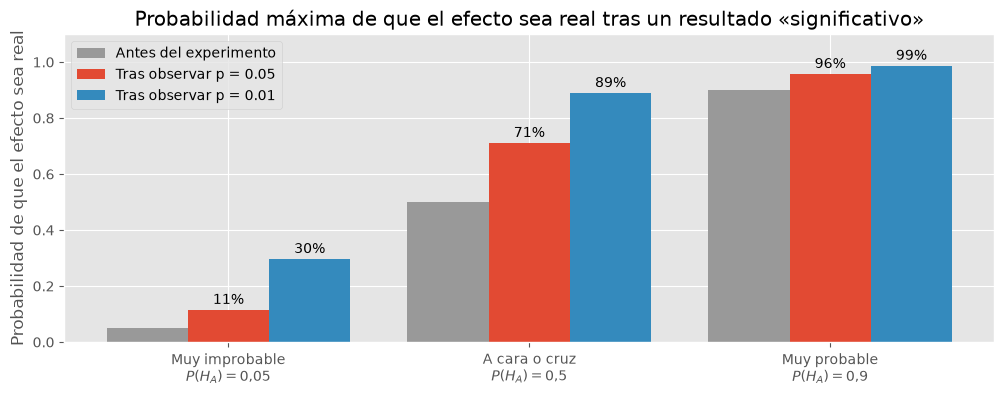

In [19]:
def prob_max_efecto_real(p, prior_ha):
    # Cota superior de P(HA | p) (Sellke, Bayarri y Berger, 2001), válida para p < 1/e
    factor_bayes_h0 = -np.e * p * np.log(p)       # cota inferior del factor de Bayes a favor de H0
    odds_h0 = (1 - prior_ha) / prior_ha * factor_bayes_h0
    return 1 / (1 + odds_h0)


priors_ha = {'Muy improbable\n$P(H_A) = 0{,}05$': 0.05,
             'A cara o cruz\n$P(H_A) = 0{,}5$': 0.5,
             'Muy probable\n$P(H_A) = 0{,}9$': 0.9}

etiquetas = list(priors_ha)
pos = np.arange(len(etiquetas))
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(pos - 0.27, list(priors_ha.values()), width=0.27, color='0.6', label='Antes del experimento')
for desp, p in [(0, 0.05), (0.27, 0.01)]:
    post = [prob_max_efecto_real(p, pa) for pa in priors_ha.values()]
    barras = ax.bar(pos + desp, post, width=0.27, label=f'Tras observar p = {p}')
    ax.bar_label(barras, labels=[f'{v:.0%}' for v in post], padding=2)
ax.set_xticks(pos, etiquetas)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Probabilidad de que el efecto sea real')
ax.set_title('Probabilidad máxima de que el efecto sea real tras un resultado «significativo»')
ax.legend(loc='upper left')
plt.show()

Si de entrada el efecto era muy improbable (una hipótesis «arriesgada»), un $p = 0{,}05$ deja la probabilidad de que sea real, **como mucho**, en torno al 11 %, y un $p = 0{,}01$ en torno al 30 %. Por eso los resultados sorprendentes con valores *p* cercanos a 0,05 se reproducen tan a menudo con dificultad, como en el ejemplo de Nuzzo.

> **Para leer:** T. Sellke, M. J. Bayarri y J. O. Berger, «Calibration of *p* values for testing precise null hypotheses», *The American Statistician* 55 (1), 62-71 (2001).

## 7. Inferencia sobre un parámetro continuo: ¿está sesgada la moneda?

Hasta ahora las hipótesis eran un conjunto finito de valores (las puertas, el número de locomotoras). Pero a menudo el parámetro es **continuo**, y la distribución a priori y la distribución a posteriori son funciones de densidad.

### 7.1 El modelo

Queremos saber si una moneda está sesgada. Suponemos que tiene una probabilidad de cara $\theta \in [0, 1]$ desconocida, y la lanzamos varias veces anotando cara (1) o cruz (0).

> **Supuesto.** Nuestras distribuciones paramétricas son **modelos generativos** del mundo: describen cómo se producen los datos.

Cada lanzamiento sigue una **distribución de Bernoulli**, que vale 1 con probabilidad $\theta$ y 0 con probabilidad $1 - \theta$:

$$ P(k \mid \theta) = \theta^k (1 - \theta)^{1-k}, \qquad k \in \{0, 1\} $$

Como los lanzamientos son independientes, la probabilidad de una secuencia $\{k_1, \dots, k_N\}$ es el producto de las probabilidades de cada lanzamiento. Si $z$ es el número de caras en $N$ lanzamientos, la **verosimilitud** es:

$$ P(D \mid \theta) = \prod_i \theta^{k_i} (1 - \theta)^{1 - k_i} = \theta^{z} (1 - \theta)^{N - z} $$

### 7.2 El teorema de Bayes para un parámetro

$$ P(\theta \mid D) = \frac{P(D \mid \theta)\, P(\theta)}{P(D)} \;\propto\; P(D \mid \theta)\, P(\theta) $$

+ $P(\theta)$, la distribución **a priori**: lo que creemos sobre el sesgo de la moneda antes de lanzarla.
+ $P(D \mid \theta)$, la **verosimilitud**: la probabilidad de obtener los resultados observados para cada valor de $\theta$.
+ $P(D)$, la **evidencia**: la probabilidad de los datos promediada sobre todos los valores posibles de $\theta$; de nuevo, solo normaliza.
+ $P(\theta \mid D)$, la distribución **a posteriori**: lo que creemos sobre $\theta$ después de ver los datos.

### 7.3 La distribución beta como distribución a priori

Para $\theta$ usaremos una **distribución beta**, definida en $[0, 1]$ y muy flexible:

$$ P(\theta \mid \alpha, \beta) = \frac{\theta^{\alpha - 1} (1 - \theta)^{\beta - 1}}{B(\alpha, \beta)} $$

donde $B(\alpha, \beta)$ es una constante de normalización. Con $\alpha = \beta = 1$ es la distribución uniforme (ninguna opinión previa); con $\alpha = \beta$ grandes, expresa la creencia de que la moneda está cerca de ser equilibrada.

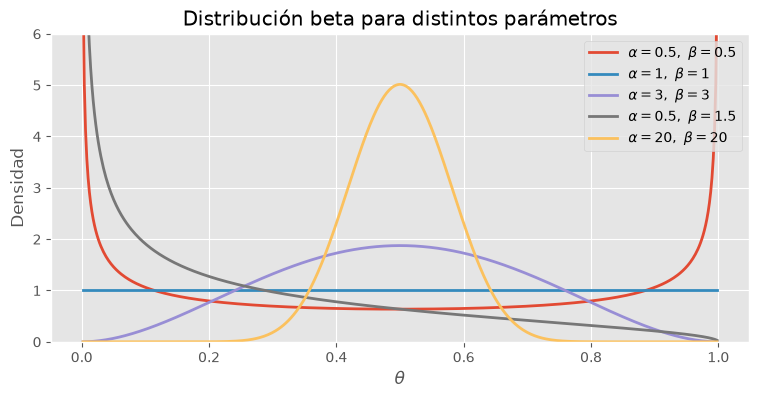

In [20]:
theta = np.linspace(0, 1, 500)[1:-1]

fig, ax = plt.subplots(figsize=(9, 4))
for a, b in [(0.5, 0.5), (1, 1), (3, 3), (0.5, 1.5), (20, 20)]:
    ax.plot(theta, stats.beta.pdf(theta, a, b), lw=2, label=f'$\\alpha = {a},\\ \\beta = {b}$')
ax.set_ylim(0, 6)
ax.set_xlabel('$\\theta$')
ax.set_ylabel('Densidad')
ax.set_title('Distribución beta para distintos parámetros')
ax.legend()
plt.show()

La razón principal para elegir la distribución beta es que es la **distribución a priori conjugada** de la verosimilitud de Bernoulli (o binomial):

> Una distribución a priori es **conjugada** de una verosimilitud si la distribución a posteriori que se obtiene pertenece a la **misma familia** que la distribución a priori, solo que con otros parámetros.

En este caso, multiplicando la verosimilitud por la distribución a priori:

$$ P(\theta \mid D) \;\propto\; \theta^{z} (1 - \theta)^{N - z} \cdot \theta^{\alpha - 1} (1 - \theta)^{\beta - 1} = \theta^{\alpha + z - 1} (1 - \theta)^{\beta + N - z - 1} $$

Es decir, si la distribución a priori es $\text{Beta}(\alpha, \beta)$ y observamos $z$ caras en $N$ lanzamientos, la distribución a posteriori es

$$ \text{Beta}(\alpha + z,\ \beta + N - z) $$

¡Actualizar consiste simplemente en **sumar las caras a $\alpha$ y las cruces a $\beta$**!

### 7.4 Cómo cambia la distribución a posteriori al acumular datos

Simulamos 500 lanzamientos de una moneda equilibrada ($\theta = 0{,}5$) y, partiendo de una distribución a priori uniforme, $\text{Beta}(1, 1)$, dibujamos la distribución a posteriori tras observar los primeros $N$ lanzamientos:

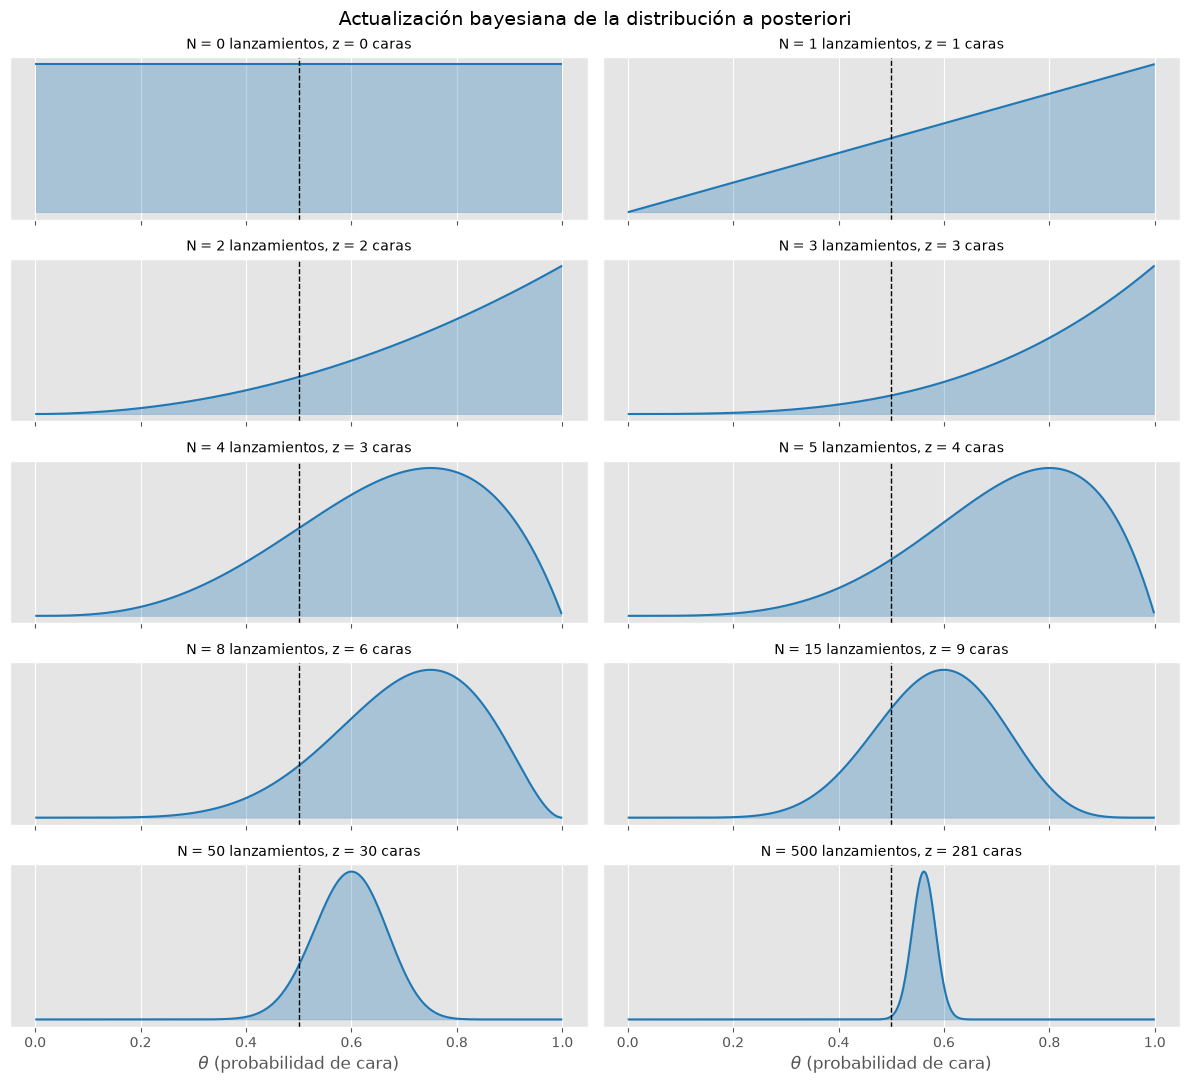

In [21]:
lanzamientos = rng.binomial(1, 0.5, size=500)     # 1 = cara, 0 = cruz
n_obs = [0, 1, 2, 3, 4, 5, 8, 15, 50, 500]

fig, axes = plt.subplots(5, 2, figsize=(12, 11), sharex=True)
for ax, N in zip(axes.flat, n_obs):
    caras = lanzamientos[:N].sum()
    dens = stats.beta.pdf(theta, 1 + caras, 1 + N - caras)
    ax.plot(theta, dens, color='tab:blue')
    ax.fill_between(theta, dens, color='tab:blue', alpha=0.3)
    ax.axvline(0.5, color='black', ls='--', lw=1)
    ax.set_title(f'N = {N} lanzamientos, z = {caras} caras', fontsize=10)
    ax.set_yticks([])
for ax in axes[-1]:
    ax.set_xlabel('$\\theta$ (probabilidad de cara)')
fig.suptitle('Actualización bayesiana de la distribución a posteriori', fontsize=14)
fig.tight_layout()
plt.show()

Con pocos datos, la distribución a posteriori es ancha (mucha incertidumbre) y se mueve mucho con cada lanzamiento. A medida que acumulamos datos, **se estrecha y se concentra alrededor del valor verdadero**, $\theta = 0{,}5$.

### 7.5 Volviendo a la moneda belga

En el notebook anterior analizamos la moneda de un euro belga que dio **140 caras en 250 lanzamientos**. El contraste frecuentista daba un valor *p* bilateral de aproximadamente 0,07: no podíamos rechazar que la moneda fuera equilibrada.

Con el enfoque bayesiano y una distribución a priori uniforme, la distribución a posteriori es $\text{Beta}(1 + 140,\ 1 + 110)$, y podemos responder directamente preguntas como «¿qué probabilidad hay de que la moneda favorezca las caras?», $P(\theta > 0{,}5 \mid D)$:

Media a posteriori de θ:        0.560
Intervalo de credibilidad 95 %: [0.498, 0.620]
P(θ > 0,5 | datos):             0.971


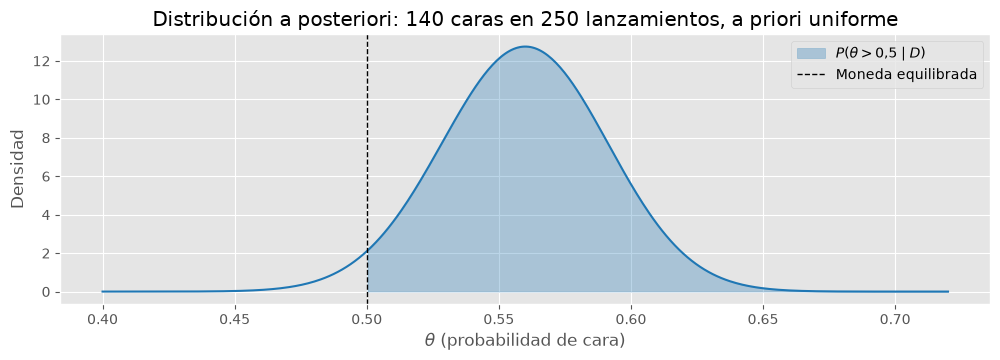

In [22]:
caras_obs, n_lanz = 140, 250
a_post, b_post = 1 + caras_obs, 1 + n_lanz - caras_obs     # a priori Beta(1, 1)
posterior_moneda = stats.beta(a_post, b_post)

ic_cred = posterior_moneda.ppf([0.025, 0.975])
print(f'Media a posteriori de θ:        {posterior_moneda.mean():.3f}')
print(f'Intervalo de credibilidad 95 %: [{ic_cred[0]:.3f}, {ic_cred[1]:.3f}]')
print(f'P(θ > 0,5 | datos):             {posterior_moneda.sf(0.5):.3f}')

theta_z = np.linspace(0.4, 0.72, 400)
dens = posterior_moneda.pdf(theta_z)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(theta_z, dens, color='tab:blue')
ax.fill_between(theta_z, dens, where=theta_z > 0.5, color='tab:blue', alpha=0.3, label='$P(\\theta > 0{,}5 \\mid D)$')
ax.axvline(0.5, color='black', ls='--', lw=1, label='Moneda equilibrada')
ax.set_xlabel('$\\theta$ (probabilidad de cara)')
ax.set_ylabel('Densidad')
ax.set_title('Distribución a posteriori: 140 caras en 250 lanzamientos, a priori uniforme')
ax.legend()
plt.show()

Partiendo de una distribución a priori que no tiene ninguna opinión sobre la moneda, hay alrededor de un **97 % de probabilidad de que la moneda favorezca las caras**. El intervalo de credibilidad del 95 % incluye por poco el 0,5.

Pero ¿es razonable una distribución a priori uniforme? Antes de lanzarla, casi todos creeríamos que una moneda de curso legal está **muy cerca** de ser equilibrada: una moneda con $\theta = 0{,}9$ nos parecería prácticamente imposible.

**Ejercicio 4**

Repite el análisis de la moneda belga con una distribución a priori que exprese la creencia de que la moneda es casi equilibrada, por ejemplo $\text{Beta}(50, 50)$, y con otra todavía más firme, $\text{Beta}(500, 500)$. Para cada una, calcula la media a posteriori, el intervalo de credibilidad del 95 % y $P(\theta > 0{,}5 \mid D)$, y dibuja en un mismo gráfico la distribución a priori y la distribución a posteriori. ¿Cómo cambian las conclusiones?

In [23]:
# Escribe aquí tu solución

## 8. Programación probabilística con PyMC

En los ejemplos anteriores podíamos calcular la distribución a posteriori **exactamente**, ya fuera porque el parámetro tomaba un número finito de valores (la locomotora) o porque la distribución a priori era conjugada (la moneda). En la mayoría de los modelos reales, con muchos parámetros, eso no es posible.

La **programación probabilística** permite especificar un modelo bayesiano de forma flexible, con una sintaxis muy cercana a la notación estadística, y obtener **muestras de la distribución a posteriori** mediante métodos de Monte Carlo basados en cadenas de Markov (**MCMC**). Con esas muestras podemos calcular medias, intervalos de credibilidad o cualquier otra cantidad, igual que hacíamos con las estimaciones *bootstrap*.

Usaremos [PyMC](https://www.pymc.io/), una biblioteca de código abierto para Python (es la sucesora de PyMC3).

In [24]:
import pymc as pm
import arviz as az

### 8.1 Un modelo de regresión lineal bayesiana

Como primer ejemplo, consideremos una **regresión lineal** en la que la variable respuesta $Y$ sigue una distribución normal cuya media es una función lineal de dos predictores, $X_1$ y $X_2$:

$$ Y \sim \mathcal{N}(\mu, \sigma^2), \qquad \mu = \alpha + \beta_1 X_1 + \beta_2 X_2 $$

Como distribuciones a priori usamos normales centradas en 0 con desviación estándar 10 para los coeficientes, lo que expresa poca información sobre sus valores. Como $\sigma$ debe ser positiva, le asignamos una distribución **seminormal** (una normal truncada en 0):

$$ \alpha \sim \mathcal{N}(0, 10^2), \qquad \beta_i \sim \mathcal{N}(0, 10^2), \qquad \sigma \sim |\mathcal{N}(0, 10^2)| $$

Para poder comprobar los resultados, generamos datos simulados con parámetros conocidos: $\alpha = 1$, $\beta_1 = 1$, $\beta_2 = 2{,}5$ y $\sigma = 1$.

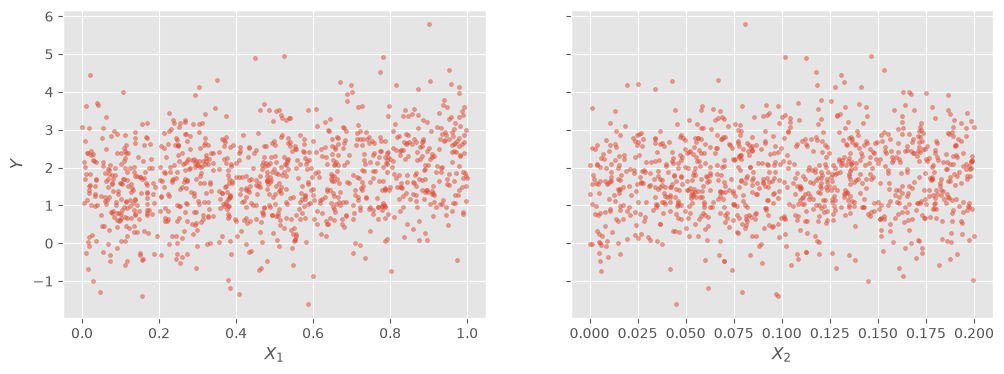

In [25]:
# Valores verdaderos de los parámetros
alpha_real, sigma_real = 1, 1
beta_real = [1, 2.5]
n_obs_reg = 1000

X1 = rng.random(n_obs_reg)
X2 = rng.random(n_obs_reg) / 5
Y = alpha_real + beta_real[0] * X1 + beta_real[1] * X2 + rng.normal(0, sigma_real, size=n_obs_reg)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax1.scatter(X1, Y, s=8, alpha=0.5)
ax1.set_xlabel('$X_1$')
ax1.set_ylabel('$Y$')
ax2.scatter(X2, Y, s=8, alpha=0.5)
ax2.set_xlabel('$X_2$')
plt.show()

### 8.2 Especificación del modelo

En PyMC, el modelo se escribe casi igual que en la notación estadística. Todas las variables definidas dentro del bloque `with` se añaden al modelo:

In [26]:
with pm.Model() as modelo_reg:
    # Distribuciones a priori de los parámetros desconocidos
    alpha = pm.Normal('alpha', mu=0, sigma=10)
    beta = pm.Normal('beta', mu=0, sigma=10, shape=2)
    sigma = pm.HalfNormal('sigma', sigma=10)

    # Valor esperado de la respuesta
    mu = alpha + beta[0] * X1 + beta[1] * X2

    # Verosimilitud de las observaciones
    Y_obs = pm.Normal('Y_obs', mu=mu, sigma=sigma, observed=Y)

### 8.3 Ajuste del modelo

Una vez especificado el modelo, queremos obtener la **distribución a posteriori de los parámetros desconocidos**. Hay dos enfoques:

+ buscar el **máximo a posteriori (MAP)** con un método de optimización, lo que proporciona solo una estimación puntual;
+ obtener **muestras de la distribución a posteriori** con un método MCMC, lo que nos da la distribución completa.

Primero, el MAP:

In [27]:
with modelo_reg:
    estimacion_map = pm.find_MAP(progressbar=False)

print(f"alpha = {estimacion_map['alpha']:.3f}")
print(f"beta  = {np.round(estimacion_map['beta'], 3)}")
print(f"sigma = {estimacion_map['sigma']:.3f}")

/var/folders/y2/01wtqy1562jbjdrmg6l76pz80000gn/T/ipykernel_8951/872054479.py:2: FutureWarning: `find_MAP` will return an `InferenceData` instead of a dict in a future release. Pass `return_inferencedata=True` to adopt the new behavior now.
  estimacion_map = pm.find_MAP(progressbar=False)
/var/folders/y2/01wtqy1562jbjdrmg6l76pz80000gn/T/ipykernel_8951/872054479.py:2: FutureWarning: `find_MAP` will jitter its initial point by default in a future release. Pass `jitter=True` to adopt that now, or `jitter=False` to keep the current behavior.
  estimacion_map = pm.find_MAP(progressbar=False)


alpha = 1.168
beta  = [0.794 1.369]
sigma = 1.009


Para el muestreo, PyMC elige automáticamente el algoritmo más adecuado. Para parámetros continuos, como aquí, usa **NUTS** (*No-U-Turn Sampler*), un método MCMC muy eficiente en modelos con muchos parámetros continuos. Obtenemos 2000 muestras en cada una de 4 cadenas independientes, después de 1000 iteraciones de ajuste (*tune*) que se descartan:

In [28]:
with modelo_reg:
    traza = pm.sample(2000, tune=1000, chains=4, random_seed=2026, progressbar=False)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 15 seconds.


### 8.4 Análisis de la distribución a posteriori

El resultado contiene las muestras de cada parámetro. Para cada uno, dibujamos su distribución a posteriori (izquierda) y la evolución de las muestras en cada cadena (derecha). Una buena **traza** se parece a un ruido sin tendencias y las cadenas se solapan entre sí, señal de que el muestreo ha convergido.

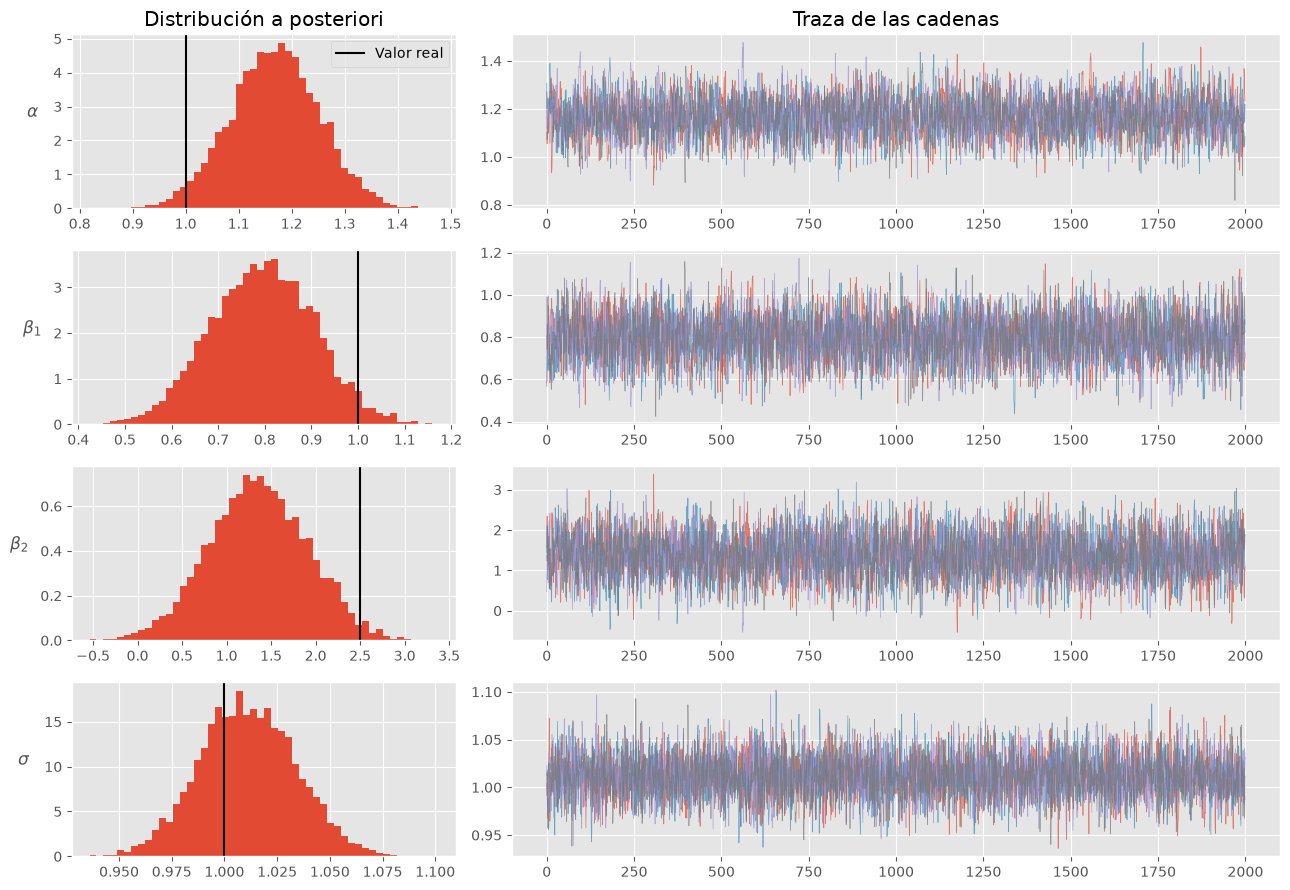

In [29]:
muestras_reg = {
    '$\\alpha$': traza.posterior['alpha'].values,
    '$\\beta_1$': traza.posterior['beta'].values[..., 0],
    '$\\beta_2$': traza.posterior['beta'].values[..., 1],
    '$\\sigma$': traza.posterior['sigma'].values,
}
valores_reales = [alpha_real, beta_real[0], beta_real[1], sigma_real]

fig, axes = plt.subplots(4, 2, figsize=(13, 9), gridspec_kw={'width_ratios': [1, 2]})
for (nombre, m), real, (ax1, ax2) in zip(muestras_reg.items(), valores_reales, axes):
    ax1.hist(m.ravel(), bins=50, density=True)
    ax1.axvline(real, color='black', lw=1.5, label='Valor real')
    ax1.set_ylabel(nombre, rotation=0, labelpad=15)
    for cadena in m:
        ax2.plot(cadena, lw=0.5, alpha=0.7)
axes[0, 0].legend()
axes[0, 0].set_title('Distribución a posteriori')
axes[0, 1].set_title('Traza de las cadenas')
fig.tight_layout()
plt.show()

A partir de las muestras podemos calcular cualquier resumen, igual que con las estimaciones *bootstrap*: media, desviación estándar e intervalo de credibilidad del 95 % (percentiles 2,5 y 97,5).

In [30]:
pd.DataFrame({
    'valor real': valores_reales,
    'media': [m.mean() for m in muestras_reg.values()],
    'desv. estándar': [m.std() for m in muestras_reg.values()],
    'IC 95 % inf.': [np.percentile(m, 2.5) for m in muestras_reg.values()],
    'IC 95 % sup.': [np.percentile(m, 97.5) for m in muestras_reg.values()],
}, index=['alpha', 'beta_1', 'beta_2', 'sigma']).round(3)

,valor real,media,desv. estándar,IC 95 % inf.,IC 95 % sup.
alpha,1.0,1.168,0.084,1.003,1.332
beta_1,1.0,0.795,0.110,0.581,1.008
beta_2,2.5,1.359,0.552,0.269,2.416
sigma,1.0,1.011,0.023,0.968,1.056


En este caso los cuatro intervalos de credibilidad contienen los valores reales (los de $\alpha$ y $\beta_1$, por poco: son intervalos del 95 %, y con otra semilla alguno podría no contenerlo). Observa que el de $\beta_2$ es mucho más ancho que el de $\beta_1$: como $X_2$ varía poco (entre 0 y 0,2), los datos contienen poca información sobre su coeficiente.

La biblioteca [ArviZ](https://www.arviz.org/), que se instala con PyMC, ofrece este tipo de resúmenes y gráficos, junto con diagnósticos de convergencia como $\hat{R}$ (`r_hat`), que debe ser muy cercano a 1:

In [31]:
az.summary(traza)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha,1.168,0.084,1,1.3,3775,4076,1.00,0.0014,0.001
beta[0],0.795,0.111,0.62,0.97,4388,4765,1.00,0.0017,0.0012
beta[1],1.36,0.55,0.49,2.3,4847,5025,1.00,0.0079,0.0059
sigma,1.0112,0.0227,0.98,1,6178,5299,1.00,0.00029,0.00025


### 8.5 Recordatorio: las distribuciones de Poisson y exponencial

Para el siguiente ejemplo necesitamos dos distribuciones habituales.

**Distribución de Poisson (discreta).** Una variable aleatoria $Z$ sigue una distribución de Poisson si

$$ P(Z = k) = \frac{\lambda^k e^{-\lambda}}{k!}, \qquad k = 0, 1, 2, \dots $$

Modela el **número de sucesos que ocurren en un intervalo fijo de tiempo o espacio** cuando estos ocurren con una tasa media conocida e independientemente unos de otros (por ejemplo, el número de accidentes de tráfico de un día). El parámetro $\lambda > 0$ es la **intensidad**, y coincide con el valor esperado: $\mathbb{E}[Z \mid \lambda] = \lambda$. Los valores de $k$ solo pueden ser enteros no negativos, lo que la hace adecuada para recuentos.

**Distribución exponencial (continua).** Su función de densidad es

$$ f(z \mid \lambda) = \lambda e^{-\lambda z}, \qquad z \geq 0 $$

Como la de Poisson, solo toma valores no negativos, pero puede tomar **cualquier** valor real, no solo enteros. Es adecuada para tiempos o para cualquier magnitud positiva, como una tasa. Su valor esperado es $\mathbb{E}[Z \mid \lambda] = 1/\lambda$.

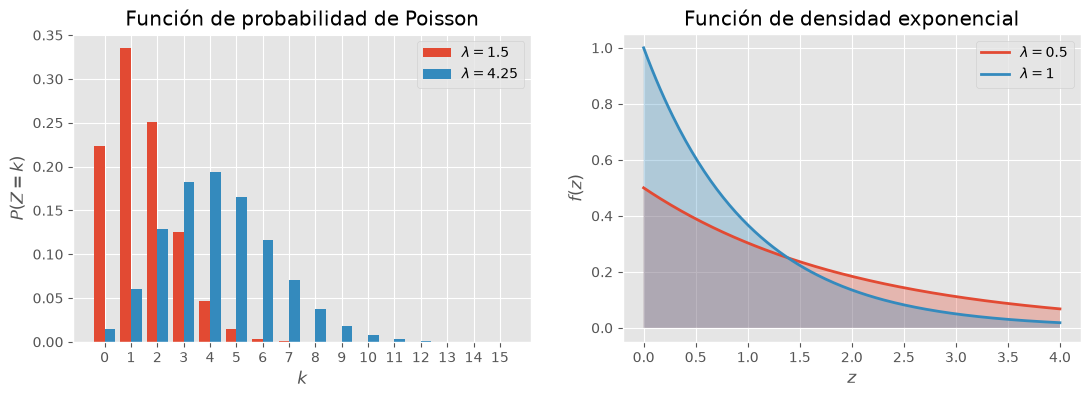

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

k = np.arange(16)
for lam, desp in [(1.5, -0.2), (4.25, 0.2)]:
    ax1.bar(k + desp, stats.poisson.pmf(k, lam), width=0.4, label=f'$\\lambda = {lam}$')
ax1.set_xticks(k)
ax1.set_xlabel('$k$')
ax1.set_ylabel('$P(Z = k)$')
ax1.set_title('Función de probabilidad de Poisson')
ax1.legend()

z = np.linspace(0, 4, 200)
for lam in [0.5, 1]:
    dens = stats.expon.pdf(z, scale=1 / lam)
    ax2.plot(z, dens, lw=2, label=f'$\\lambda = {lam}$')
    ax2.fill_between(z, dens, alpha=0.3)
ax2.set_xlabel('$z$')
ax2.set_ylabel('$f(z)$')
ax2.set_title('Función de densidad exponencial')
ax2.legend()
plt.show()

En la práctica, **$\lambda$ es desconocido**: solo vemos $Z$, y debemos ir hacia atrás para averiguar $\lambda$. Esta es, precisamente, la pregunta que motiva la estadística. La inferencia bayesiana no intenta adivinar el valor exacto de $\lambda$, sino que describe nuestras **creencias** sobre él con una distribución de probabilidad.

### 8.6 Ejemplo: ¿ha cambiado el comportamiento de un usuario?

Este ejemplo procede de *Bayesian Methods for Hackers* (C. Davidson-Pilon, 2013). El fichero `txtdata.csv` contiene el número de mensajes de texto que un usuario ha recibido cada día durante 74 días (de hecho, son los mensajes del propio autor del libro). ¿Han cambiado sus hábitos con el tiempo, de forma gradual o brusca?

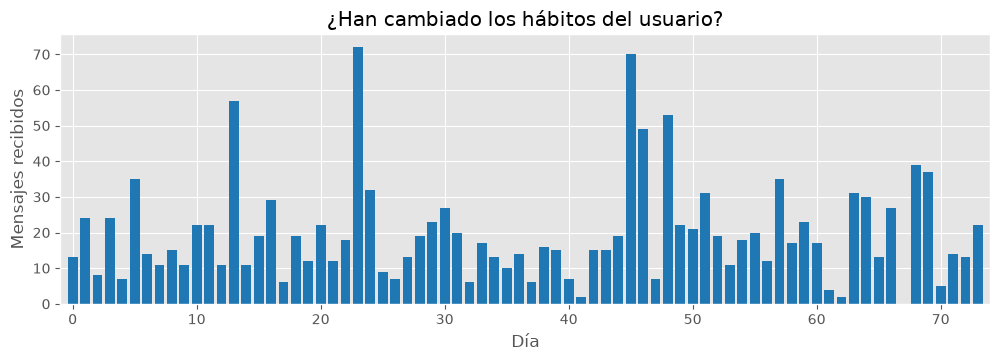

In [33]:
mensajes = np.loadtxt('files/txtdata.csv')
n_dias = len(mensajes)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(np.arange(n_dias), mensajes, color='tab:blue')
ax.set_xlim(-1, n_dias)
ax.set_xlabel('Día')
ax.set_ylabel('Mensajes recibidos')
ax.set_title('¿Han cambiado los hábitos del usuario?')
plt.show()

Planteamos el siguiente modelo:

+ El número de mensajes del día $i$, $C_i$, sigue una distribución de Poisson: $C_i \sim \text{Poisson}(\lambda_i)$.
+ En algún día desconocido $\tau$, la tasa cambia: $\lambda_i = \lambda_1$ si $i < \tau$ y $\lambda_i = \lambda_2$ si $i \geq \tau$. Si $\lambda_1 \approx \lambda_2$, no ha habido cambio.
+ Distribuciones a priori: $\lambda_1$ y $\lambda_2$ siguen una exponencial con media igual a la media de los datos, y $\tau$ es uniforme entre todos los días posibles.

Tenemos un parámetro discreto ($\tau$), así que PyMC combinará automáticamente NUTS para las tasas con un método de Metropolis para $\tau$.

In [34]:
with pm.Model() as modelo_msg:
    lambda_1 = pm.Exponential('lambda_1', 1 / mensajes.mean())
    lambda_2 = pm.Exponential('lambda_2', 1 / mensajes.mean())
    tau = pm.DiscreteUniform('tau', lower=0, upper=n_dias - 1)

    dia = np.arange(n_dias)
    lambda_ = pm.math.switch(tau > dia, lambda_1, lambda_2)   # λ1 antes de τ, λ2 a partir de τ

    obs = pm.Poisson('obs', lambda_, observed=mensajes)

    traza_msg = pm.sample(5000, tune=2000, chains=4, random_seed=2026, progressbar=False)

m_lambda_1 = traza_msg.posterior['lambda_1'].values.ravel()
m_lambda_2 = traza_msg.posterior['lambda_2'].values.ravel()
m_tau = traza_msg.posterior['tau'].values.ravel()

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>NUTS: [lambda_1, lambda_2]
>Metropolis: [tau]


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Sampling 4 chains for 2_000 tune and 5_000 draw iterations (8_000 + 20_000 draws total) took 15 seconds.


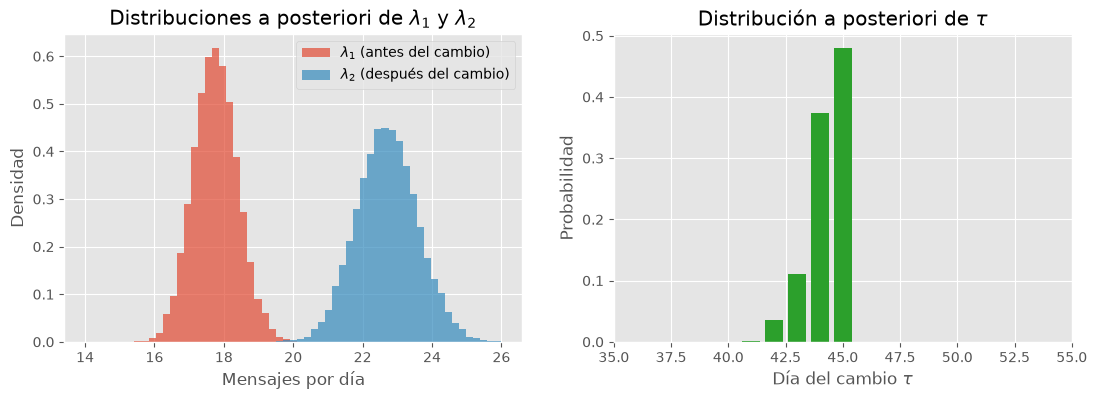

Media a posteriori de λ1: 17.8 mensajes/día
Media a posteriori de λ2: 22.7 mensajes/día
Día más probable del cambio: 45
P(λ2 > λ1 | datos) = 1.000


In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

bins = np.linspace(14, 26, 60)
ax1.hist(m_lambda_1, bins=bins, density=True, alpha=0.7, label='$\\lambda_1$ (antes del cambio)')
ax1.hist(m_lambda_2, bins=bins, density=True, alpha=0.7, label='$\\lambda_2$ (después del cambio)')
ax1.set_xlabel('Mensajes por día')
ax1.set_ylabel('Densidad')
ax1.set_title('Distribuciones a posteriori de $\\lambda_1$ y $\\lambda_2$')
ax1.legend()

dias_tau, cuentas = np.unique(m_tau, return_counts=True)
ax2.bar(dias_tau, cuentas / len(m_tau), color='tab:green')
ax2.set_xlim(35, 55)
ax2.set_xlabel('Día del cambio $\\tau$')
ax2.set_ylabel('Probabilidad')
ax2.set_title('Distribución a posteriori de $\\tau$')
plt.show()

print(f'Media a posteriori de λ1: {m_lambda_1.mean():.1f} mensajes/día')
print(f'Media a posteriori de λ2: {m_lambda_2.mean():.1f} mensajes/día')
print(f'Día más probable del cambio: {dias_tau[np.argmax(cuentas)]}')
print(f'P(λ2 > λ1 | datos) = {np.mean(m_lambda_2 > m_lambda_1):.3f}')

Las dos distribuciones a posteriori de $\lambda$ están claramente separadas: es prácticamente seguro que **la tasa de mensajes aumentó**, de unos 18 a unos 23 mensajes diarios. Además, la distribución a posteriori de $\tau$ está muy concentrada: el cambio se produjo, casi con toda seguridad, entre los días 43 y 45.

Por último, combinamos las muestras para obtener el **número esperado de mensajes de cada día**: para cada muestra, la tasa del día $i$ es $\lambda_1$ si $i < \tau$ y $\lambda_2$ en caso contrario, y promediamos sobre todas las muestras.

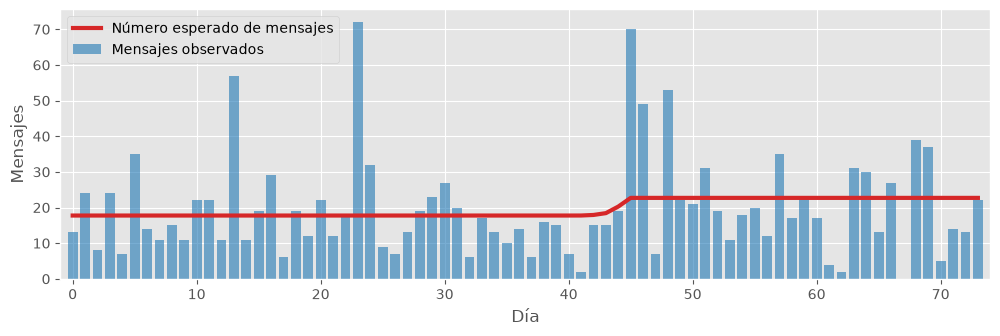

In [36]:
dias = np.arange(n_dias)
antes = dias[None, :] < m_tau[:, None]          # (muestras × días): ¿el día es anterior al cambio?
esperados = np.where(antes, m_lambda_1[:, None], m_lambda_2[:, None]).mean(axis=0)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(dias, mensajes, color='tab:blue', alpha=0.6, label='Mensajes observados')
ax.plot(dias, esperados, color='tab:red', lw=3, label='Número esperado de mensajes')
ax.set_xlim(-1, n_dias)
ax.set_xlabel('Día')
ax.set_ylabel('Mensajes')
ax.legend(loc='upper left')
plt.show()

## 9. Conclusiones

### Resumen de la inferencia bayesiana

+ La probabilidad expresa un **grado de creencia**, y el **teorema de Bayes** indica cómo actualizarla de forma coherente a la vista de los datos: *a posteriori* $\propto$ *a priori* $\times$ verosimilitud.
+ La distribución a posteriori de un dato es la distribución a priori del siguiente: el aprendizaje es **secuencial**.
+ Con pocos datos, el resultado depende mucho de la distribución a priori; **a medida que llegan datos, los datos dominan** y distribuciones a priori distintas llevan a conclusiones parecidas. La información de contexto, bien usada, hace las estimaciones más robustas.
+ La distribución a posteriori se resume con **estimaciones puntuales** (media, mediana, MAP) e **intervalos de credibilidad**, que sí admiten una interpretación probabilística directa.
+ En los modelos sencillos, la distribución a posteriori se calcula exactamente (con una rejilla de valores o con distribuciones a priori conjugadas); en los modelos complejos, se aproxima con **muestras MCMC**, por ejemplo con PyMC.

### Frecuentista y bayesiano, cara a cara

| | Frecuentista | Bayesiano |
|---|---|---|
| Probabilidad | frecuencia a largo plazo | grado de creencia |
| Parámetros | fijos y desconocidos | descritos con una distribución de probabilidad |
| Información previa | no se incorpora formalmente | se incorpora con la distribución a priori |
| Resultado | estimación puntual, IC, valor *p* | distribución a posteriori |
| Intervalo | de **confianza**: el 95 % se refiere al procedimiento | de **credibilidad**: 95 % de probabilidad de contener el parámetro |
| Hipótesis | $P(\text{datos} \mid H_0)$ | $P(H \mid \text{datos})$ |

Los dos enfoques no son enemigos: con muchos datos y distribuciones a priori poco informativas suelen dar resultados numéricamente parecidos, y en muchos problemas prácticos se usan de forma complementaria. Lo importante es **saber qué pregunta responde cada uno** y comunicar los resultados con la interpretación correcta.

### Para saber más

+ C. Davidson-Pilon, [*Bayesian Methods for Hackers*](https://github.com/CamDavidsonPilon/Probabilistic-Programming-and-Bayesian-Methods-for-Hackers).
+ A. B. Downey, [*Think Bayes*](https://greenteapress.com/wp/think-bayes/), 2.ª ed., O'Reilly (2021).
+ A. Gelman *et al.*, [*Bayesian Data Analysis*](http://www.stat.columbia.edu/~gelman/book/), 3.ª ed., CRC Press (2013).